# Project 1

Welcome to the first NLP1 project. The goal of the first tutorial was to get you familiar with text segmentation and simple text classification for topic detection.
Given the skills you have developed in the first week, you will now be applying them within a different dataset and task.

We are recommending a set of tasks and associated datasets; using those, you will be experimenting on problems introduced during the tutorials. You will be applying hands-on the experiments you have already explored in the last tutorial, and taking a deeper dive: extending your experiments, trying different set ups, possibly considering different evaluation techniques and analysing errors. 

The week after the deadline, your TA will perform a short oral assessment of the skills and knowledge you acquired (make sure to check the official schedule for this), probing you to answer questions about what you learnt, about what you did and about why you did the things you did (as opposed to some reasonable alternatives) as well as pros and cons of your method, and so on. 

As the tutorials will be building upon your knowledge throughout the weeks, the task and dataset you choose now will be the ones you use in projects 2 and 3; and the ones you will be finally writing about in your final blog post.  

## Get to work!

The next section has a checklist to help you not lose track of what needs to be done. Here we have a more informal guide, with prompts and questions for you. 


1. [Choose a dataset](http://nlp-illc.github.io/nlp1/). Spend some time understanding how the dataset looks and some statistics of it (e.g. how many instances of each classification label we have?)
2. Remember what we learnt during the tutorial: to develop any classifier of the kind we saw, we needed a way to segment text. Do you want to use the tokeniser we have developed? Do you need to train a new one? If you do, what hyperparameters shall you use? What data shall you use to train it? Consider that your dataset may be too small to train a tokeniser! Think whether you will need a larger resource of similar nature to train a tokeniser.
3. Start thinking how to represent your documents into features. We have experimented with token occurences and frequencies. Can you think of any other ways, possibly? 
4. We had experimented with Logistic Regression and a shallow neural network. You can experiment with and assess different architectures now and their hyper parameters (e.g. add layers, possibly change the activation functions, drop out rates).
5. Evaluate your models! Was the evaluation method adequate for your new experimental setup? Do you want to assess other aspects of performance?
6. Analyse the various models you assessed and try to decide on which is the best.

Be mindful that you will be using your experiments to write up your final blog, so make sure they are clean and neat!

You can write your own code and you can reuse code from the tutorial and its packages or from other sources. You may use coding assistants if you like, but use it mindfully as you take full responsibility for this kind of (semi-)automated coding. Also, keep a record of the kinds of things you delegate to any form of assistant, as you will be asked to disclose this in your blog post (not because we will pass a value judgement on it, but because it is a widespread and good practice to document such things).

You may use jupyter notebooks or python files, it's up to you as we will not directly assess your code. But, once again, be organised, as we will ask you to share a reproducible version of your experiments along with your blog post (again, because this is how real research is publicised). 

If you are unsure about anything, ask your TA! They are always happy to help you! Happy coding! :)

## Checklist

What **we expect you to do**:

- [ ] Compare different systems of text classification for your choice of data/task.
- Your comparisons should cover:
    - [ ] the two representation spaces in the tutorial (token indicators and bag-of-words) and an additional one of your choice.
    - [ ] the two kinds of architectures in the tutorial (log-linear and single-hidden-layer MLP) and an additional one of your choice (such as a modification of the MLP).
- [ ] Your comparisons must be based on cross-validation and a relevant metric (accuracy or else).
- [ ] You should make use of Bayesian estimation to help you analyse results in relation to a region of practical equivalence (ROPE), and you can motivate the ROPE size yourself.

What you need to **bring to the oral assessment**:
* You will be asked questions about the points above, you can bring a slide deck with up to five slides (one for each of the following topics _data and metrics_, _features_, _architectures_, _results_, _extra_); you _will not_ give a presentation, rather, these slides are to be thought of as "backup slides" that you can use to guide your answers to the questions the TA will ask you.
* You may also be asked questions about the tutorial, for those, you don't need to prepare any deliverable (a good way to prepare is to work through the tutorial and reflect on the questions there).

What you should **keep in mind** given that you will eventually write a blog post about your work throughout the course:
* Organise your code;
* Summarise your motivations and findings;
* Document your sources and any form of AI-assistance you use.

# Project-1 Implementation

Download and import the dataset before you start :)

In [3]:
import sys
from pathlib import Path

# Finds the root directory above your current folder
root = Path.cwd().parent
sys.path.insert(0, str(root))

import Project1

In [4]:
# Just checking if shit's working

bpe_demo_corpus = [
    "low lower newest widest",
    "low lowest newer wider",
]
bpe_demo_prepared_corpus = Project1.bpe.prepare_corpus(bpe_demo_corpus)
bpe_demo_prepared_corpus

['low', '▁lower', '▁newest', '▁widest', 'low', '▁lowest', '▁newer', '▁wider']

## Example Run 

In [1]:
import pandas as pd
import numpy as np
from tokenizers import Tokenizer

from dataset import my_load_dataset
from experiment_script import TextClassifier, TokenIndicator, LogisticRegressionClassifier

In [7]:
# First load the dataset
dataset, emotions = my_load_dataset()
dataset = dataset.head(1000)  # For testing, we can limit to the first 10 rows

In [8]:

tokenizer = Tokenizer.from_pretrained("bert-base-cased")
# use token ids instead of tokens for the encoder
vocab_size = tokenizer.get_vocab_size()
encoder = TokenIndicator(length=vocab_size, verbose=False)
model = LogisticRegressionClassifier()
classifier = TextClassifier(tokenizer, encoder, model, dataset, verbose=False)



Preparing data: 100%|██████████| 1000/1000 [00:00<00:00, 9383.92it/s]

Encoded data shape: (1000, 28996), Labels shape: (1000,)


In [9]:
dataset.head()

,text,emotion
2,WHY THE FUCK IS BAYLESS ISOING,2
3,To make her feel threatened,14
4,Dirty Southern Wankers,3
5,OmG pEyToN iSn'T gOoD eNoUgH tO hElP uS iN tHe...,26
6,Yes I heard abt the f bombs! That has to be wh...,15


In [12]:
X, y = classifier.prep_dataset
print(f"Encoded Data with shape:{X.shape} of type {type(X)}")  # This should print the encoded data and labels
print(f"Encoded Data with shape:{y.shape} of type {type(y)}")  # This should print the encoded data and labels

Encoded Data with shape:(1000, 28996) of type <class 'numpy.ndarray'>
Encoded Data with shape:(1000,) of type <class 'numpy.ndarray'>


Running experiments:   0%|          | 0/5 [00:00<?, ?it/s]c:\Master_Artificial_Intelligence\NLP\NLP_Projects\.venv\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
Running experiments:  20%|██        | 1/5 [00:25<01:42, 25.73s/it]c:\Master_Artificial_Intelligence\NLP\NLP_Projects\.venv\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
Running experiments:  40%|████      | 2/5 [00:48<01:12, 24.17s/it]c:\Master_Artificial_Intelligence\NLP\NLP_Projects\.venv\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
Running experiments:  60%|██████    | 3/5 [01:12<00:48, 24.12s/it]c:\Master_Artificial_Intelligence\NLP\NLP_Projects\.venv\Lib\site-

Experiment Results: [0.31437126 0.34834835 0.38138138 0.36526946 0.32432432 0.34234234
 0.32335329 0.3003003  0.32432432 0.36526946 0.3033033  0.32132132
 0.30838323 0.33933934 0.3003003 ]


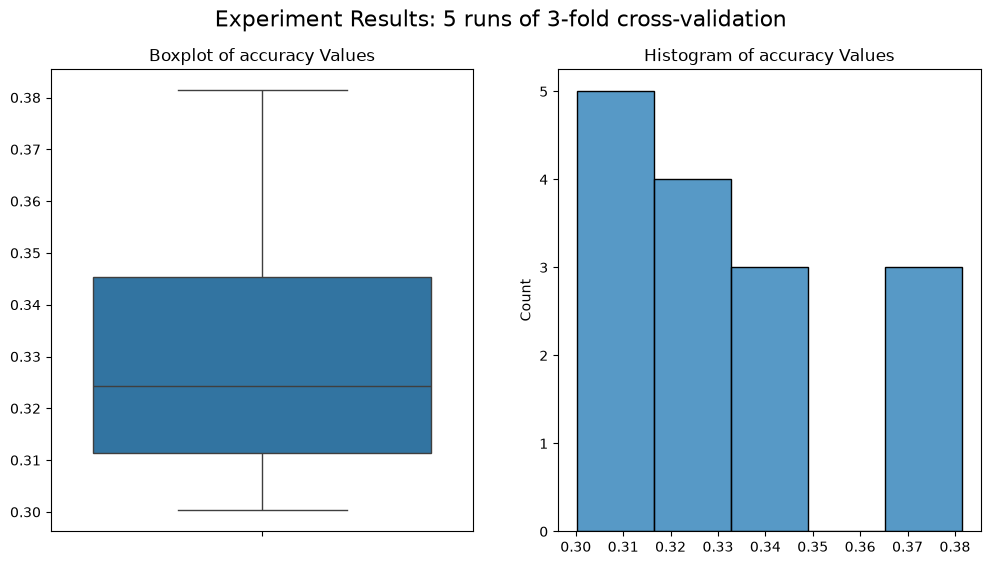

In [ ]:
results = classifier.run_experiment(number_of_runs=5, number_of_folds=3, metric="f1")
print("Experiment Results:", results)
# plot the results
classifier.visualize_results()
